In [455]:
import numpy as np
import statistics

class KNN_Classifier():
  # initiating the parameters
  def __init__(self, distance_metric):
    self.distance_metric = distance_metric

  # getting the distance metric
  def get_distance_metric(self, training_data_point, test_data_point):
    if (self.distance_metric == 'euclidean'):
      dist = 0
      for i in range (len(training_data_point)-1):
        dist = dist + (training_data_point[i] - test_data_point[i])**2
      euclidean_dist = np.sqrt(dist)
      return euclidean_dist

    elif (self.get_distance_metric == 'manhattan'):
      dist = 0
      for i in range (len(training_data_point)-1):
        dist = dist + abs(training_data_point[i] - test_data_point[i])
      manhattan_dist = dist
      return manhattan_dist

  # getting the nearest neighbors
  def nearest_neighbors(self, X_train, test_data, k):
    distance_list = []
    for training_data in X_train:
      distance = self.get_distance_metric(training_data, test_data)
      distance_list.append((training_data, distance))

    distance_list.sort(key=lambda x:x[1])

    neighbors_list = []
    for j in range(k):
      neighbors_list.append(distance_list[j][0])
    return neighbors_list

  # predict the class of new data point
  def predict(self, X_train, test_data, k):
    neighbors = self.nearest_neighbors(X_train, test_data, k)
    label = []
    for data in neighbors:

      label.append(data[-1])

    predicted_class = statistics.mode(label) #find the majority
    return predicted_class

  # predict the class for all data points in X_test
  def predict_set(self, X_train, X_test, k):
    y_pred = []
    for test_data_point in X_test:
      prediction = self.predict(X_train, test_data_point, k)
      y_pred.append(prediction)
    return y_pred

In [456]:
# import csv data to project

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

file_path = '/content/drive/MyDrive/07_Python/diabetes.csv'
df = pd.read_csv(file_path)

In [457]:
# number of rows and columns in this dataset
df.shape

(768, 9)

In [458]:
# first 5 rows of the DataFrame
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [459]:
# seperate features and targets
X = df.drop(df.columns[-1], axis=1)
Y = df[df.columns[-1]]

In [460]:
# convert the dataframe to numpy array
X = X.to_numpy()
Y = Y.to_numpy()

In [461]:
# check the numpy array

print(X)
print(Y)

[[  6.    148.     72.    ...  33.6     0.627  50.   ]
 [  1.     85.     66.    ...  26.6     0.351  31.   ]
 [  8.    183.     64.    ...  23.3     0.672  32.   ]
 ...
 [  5.    121.     72.    ...  26.2     0.245  30.   ]
 [  1.    126.     60.    ...  30.1     0.349  47.   ]
 [  1.     93.     70.    ...  30.4     0.315  23.   ]]
[1 0 1 0 1 0 1 0 1 1 0 1 0 1 1 1 1 1 0 1 0 0 1 1 1 1 1 0 0 0 0 1 0 0 0 0 0
 1 1 1 0 0 0 1 0 1 0 0 1 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 1 0 1 0 0 0 1 0 1 0
 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 1
 1 0 0 1 1 1 0 0 0 1 0 0 0 1 1 0 0 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 0 1 0 1 1 0 0 0 1 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 1 0 1 0 1 0 0 0 0 0
 1 1 1 1 1 0 0 1 1 0 1 0 1 1 1 0 0 0 0 0 0 1 1 0 1 0 0 0 1 1 1 1 0 1 1 1 1
 0 0 0 0 0 1 0 0 1 1 0 0 0 1 1 1 1 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0
 1 0 1 0 0 1 0 1 0 0 1 1 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 0 1 0 0 0 1 1 1 0 0
 1 0 1 0 1 1 0 1 0 0 1 0 1 1 0 0 1 0 1 0 0 1 0 1 0 1 1 1 0 0 1 0

In [462]:
# train test split 80% train and 20% test
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=2)

In [463]:
# check the dimension of the data, train and test

print(X.shape, X_train.shape, X_test.shape)

(768, 8) (614, 8) (154, 8)


In [464]:
print(X_train)

[[0.00e+00 1.19e+02 0.00e+00 ... 3.24e+01 1.41e-01 2.40e+01]
 [6.00e+00 1.05e+02 7.00e+01 ... 3.08e+01 1.22e-01 3.70e+01]
 [1.00e+00 1.89e+02 6.00e+01 ... 3.01e+01 3.98e-01 5.90e+01]
 ...
 [1.10e+01 8.50e+01 7.40e+01 ... 3.01e+01 3.00e-01 3.50e+01]
 [4.00e+00 1.12e+02 7.80e+01 ... 3.94e+01 2.36e-01 3.80e+01]
 [0.00e+00 8.60e+01 6.80e+01 ... 3.58e+01 2.38e-01 2.50e+01]]


In [465]:
# combine X_train and Y_train because "predict function" need combined train (features and targets)
X_train = np.insert(X_train, X_train.shape[1], Y_train, axis=1)

In [466]:
print(X_train)

[[0.00e+00 1.19e+02 0.00e+00 ... 1.41e-01 2.40e+01 1.00e+00]
 [6.00e+00 1.05e+02 7.00e+01 ... 1.22e-01 3.70e+01 0.00e+00]
 [1.00e+00 1.89e+02 6.00e+01 ... 3.98e-01 5.90e+01 1.00e+00]
 ...
 [1.10e+01 8.50e+01 7.40e+01 ... 3.00e-01 3.50e+01 0.00e+00]
 [4.00e+00 1.12e+02 7.80e+01 ... 2.36e-01 3.80e+01 0.00e+00]
 [0.00e+00 8.60e+01 6.80e+01 ... 2.38e-01 2.50e+01 0.00e+00]]



*   X_train = training data with features and target
*   X_test = test data without target

In [467]:
# find the prediction accuracies for all k values 1, 2, 3, 4, 5

k_values = [1, 2, 3, 4, 5]
accuracies = []
for k in k_values:
  classifier = KNN_Classifier(distance_metric = 'euclidean')
  y_pred = classifier.predict_set(X_train, X_test, k)
  accuracy = accuracy_score(Y_test, y_pred)
  accuracies.append(accuracy)
  print(f"k = {k}: Accuracy = {accuracies[k-1]}")

k = 1: Accuracy = 0.6753246753246753
k = 2: Accuracy = 0.6753246753246753
k = 3: Accuracy = 0.6818181818181818
k = 4: Accuracy = 0.6883116883116883
k = 5: Accuracy = 0.7272727272727273


In [468]:
# find the best k value with highest accuracy

max_accuracy =max(accuracies)
max_accuracy_index = accuracies.index(max_accuracy)

best_k = k_values[max_accuracy_index]
print(f"(K value = {best_k}) got the highest accuracy: {max_accuracy}")

(K value = 5) got the highest accuracy: 0.7272727272727273


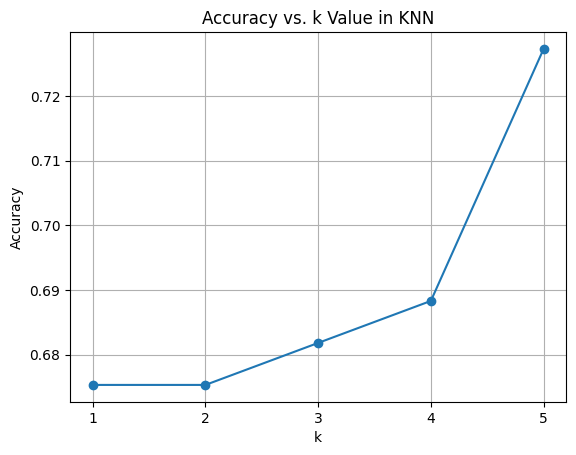

In [469]:
# Visualization
import matplotlib.pyplot as plt
plt.plot(k_values, accuracies, marker='o')
plt.title('Accuracy vs. k Value in KNN')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.xticks(k_values)  # Set x-axis ticks to k_values
plt.grid(True)
plt.show()